# IA26_P01_G02 — Agente de routing para distribuição de produtos locais
**Inteligência Artificial 2026/27 · Licenciatura em Engenharia de Sistemas Informáticos (IPCA)**  
**Trabalho Prático 1 · Notebook 01 — Introdução e Análise Exploratória de Dados (EDA)**

| Nome | Nº de aluno |
|---|---|
| André Rodrigues | 26900 |
| Tiago Gonçalves | 29389 |
| Fábio Ferreira | 29365 |
| Alexandre Silva | 29382 |

Repositório: https://github.com/FabioFerreira2005/IA26_P01_G02

## 0. Introdução

### 0.1 Contexto
Na União Europeia tem crescido a procura por alimentos produzidos localmente. As cadeias de abastecimento curtas reduzem as emissões associadas ao transporte e o desperdício alimentar quando comparadas com a distribuição de longa distância. No entanto, os pequenos produtores enfrentam custos logísticos elevados e uma forte volatilidade de preços, em particular nas frutas e legumes, cujos preços subiram significativamente nos últimos anos.

Este projeto enquadra-se numa **plataforma digital que liga três tipos de atores**:

- **Produtores** — pequenas explorações agrícolas locais que oferecem fruta, legumes e outros produtos;
- **Clientes** — fazem encomendas e escolhem o local onde as querem receber (casa, loja, restaurante, …);
- **Centros de recolha (armazéns)** — agregam os produtos antes da distribuição e são a base de uma frota de veículos.

O cenário cobre o **distrito de Braga** (incluindo a Póvoa de Varzim) e é suportado por um conjunto de dados sintético em CSV.

### 0.2 O problema
O desafio central é o **routing**: decidir que veículo faz cada recolha e cada entrega, e por que ordem, de modo a minimizar a distância percorrida, respeitando:

- o **fluxo obrigatório** produtor → armazém → local de entrega (todos os produtos passam pelo centro de recolha);
- as **janelas de disponibilidade** de cada produto no produtor e as **janelas de entrega** de cada encomenda;
- a **capacidade** (kg) de cada veículo;
- os **tempos de serviço** em cada paragem e de manuseamento no armazém, e o **tempo máximo de permanência** no armazém (`rules.csv`).

Trata-se de uma variante do *Pickup and Delivery Problem with Time Windows* (PDPTW) com passagem obrigatória por um ponto de consolidação.

### 0.3 Objetivo
Desenvolver um **agente inteligente** que, a partir dos dados da plataforma, encontre rotas de recolha e entrega eficientes e viáveis, aplicando e comparando técnicas de IA:

1. **Pesquisa informada** — Greedy Best-First e A\* com duas heurísticas próprias, usando a Pesquisa de Custo Uniforme (UCS) para validar a solução ótima;
2. **Problemas de Satisfação de Restrições (CSP)** — janelas temporais, capacidade e permanência no armazém como restrições, com a biblioteca `python-constraint`;
3. **Pesquisa local** (extra) — Hill-Climbing para melhorar a solução obtida pelo Greedy.

### 0.4 Organização do trabalho
| Fase | Entregável |
|---|---|
| Introdução e EDA *(este notebook)* | `01_eda_tiny.ipynb` |
| Modelação | `model.py` (classes `Problem`, `Request`, `Vehicle`, `State`, função de custo e verificador de viabilidade) + testes |
| Pesquisa informada | Rotas para os 2 veículos do conjunto *tiny*, nós expandidos por algoritmo |
| CSP | Formulação (variáveis, domínios, restrições), atribuição viável e nº de backtracks |
| Pesquisa local | Curvas de custo por iteração |
| Análise de resultados e conclusão | Comparação de algoritmos, tempos de execução, melhorias futuras |

### 0.5 Dados
São fornecidos dois conjuntos de dados em `docs/`, ambos com 12 ficheiros CSV e o mesmo esquema:

- `data_tiny` — instância pequena, analisada neste notebook;
- `data_small_30_31oct2026` — instância maior, comparada com a *tiny* no final da EDA.

Para reproduzir: `pip install -r requirements.txt` e executar todas as células (*Run All*). Para analisar o conjunto *small*, basta alterar a variável `DATA` na secção 1.1.

## 1. Análise Exploratória de Dados (EDA)

Antes de modelar o problema e implementar os algoritmos, estudamos o conjunto **tiny** para:

- ler os dados para memória e confirmar o tipo de cada campo (*parsing*);
- contar os elementos de cada tipo e grupo de dados;
- confirmar que os dados estão íntegros e coerentes entre si;
- caracterizar as encomendas, as janelas temporais, as distâncias e a carga face à capacidade;
- verificar se cada pedido é exequível com as regras de operação.

As conclusões desta secção justificam decisões tomadas nas fases seguintes.

### 1.1 Leitura dos dados (*parsing*)
Os 12 ficheiros CSV são lidos com `pandas` para `DataFrame`s. A função `carregar` lê uma pasta inteira e converte as colunas de datas para `datetime`, o que permite comparar horas e calcular durações. Usamos uma função para poder repetir a leitura com o conjunto *small* na secção 1.12.

In [1]:
import itertools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from IPython.display import display

DATA = "docs/data_tiny/"          # alterar para "docs/data_small_30_31oct2026/" para o outro conjunto

FICHEIROS = ["localities", "producers", "products", "collection_centers", "vehicles", "customers",
             "delivery_locations", "orders", "order_items", "locations", "distance_matrix", "rules"]
DATE_COLS = ["availability_start", "availability_end", "delivery_start", "delivery_end"]

def carregar(pasta):
    """Lê todos os CSVs de uma pasta para um dicionário {nome: DataFrame}."""
    t = {nome: pd.read_csv(pasta + nome + ".csv") for nome in FICHEIROS}
    t["orders"]["order_datetime"] = pd.to_datetime(t["orders"]["order_datetime"])
    for col in DATE_COLS:
        t["order_items"][col] = pd.to_datetime(t["order_items"][col])
    return t

tables = carregar(DATA)

# uma variável por tabela, para facilitar a leitura do código
localities = tables["localities"];        producers  = tables["producers"]
products   = tables["products"];          centers    = tables["collection_centers"]
vehicles   = tables["vehicles"];          customers  = tables["customers"]
deliv_locs = tables["delivery_locations"]; orders    = tables["orders"]
items      = tables["order_items"];       locations  = tables["locations"]
dist       = tables["distance_matrix"];   rules      = tables["rules"]

# dicionário de dados: dimensão e campos de cada tabela
pd.DataFrame([{"tabela": k, "linhas": len(v), "colunas": v.shape[1], "campos": ", ".join(v.columns)}
              for k, v in tables.items()]).set_index("tabela")

,linhas,colunas,campos
tabela,,,
localities,49,6,"locality_id, name, municipality, district, lat..."
producers,3,6,"producer_id, name, locality_id, address, phone..."
products,15,6,"product_id, producer_id, name, category, unit,..."
collection_centers,1,5,"center_id, name, locality_id, address, capacit..."
vehicles,2,6,"vehicle_id, plate, center_id, capacity_kg, ref..."
customers,12,5,"customer_id, name, locality_id, phone, email"
delivery_locations,5,5,"delivery_location_id, name, locality_id, addre..."
orders,12,5,"order_id, customer_id, delivery_location_id, o..."
order_items,40,9,"order_item_id, order_id, product_id, quantity,..."


Confirmamos o tipo de dados dos campos da tabela principal, `order_items`: as janelas temporais foram convertidas para `datetime64` e as quantidades e pesos são numéricos.

In [2]:
items.dtypes.to_frame("tipo")

,tipo
order_item_id,int64
order_id,int64
product_id,int64
quantity,float64
weight_kg,float64
availability_start,datetime64[us]
availability_end,datetime64[us]
delivery_start,datetime64[us]
delivery_end,datetime64[us]


### 1.2 Contagem por tipo e grupo
Para cada grupo de dados contamos quantos elementos existem de cada tipo. Isto dá uma visão geral da composição do problema: que tipos de paragem existem, que produtos, em que estado estão as encomendas, onde estão os atores, etc.

In [3]:
def contar(df, col, titulo):
    """Conta os elementos de cada valor de uma coluna e mostra a tabela."""
    print(titulo)
    display(df[col].value_counts().rename_axis(col).to_frame("nº"))

contar(locations,  "location_type", "Paragens por tipo")
contar(deliv_locs, "location_type", "Locais de entrega por tipo")
contar(products,   "category",      "Produtos por categoria")
contar(products,   "unit",          "Produtos por unidade de medida")
contar(products,   "producer_id",   "Produtos por produtor")
contar(orders,     "status",        "Encomendas por estado")
contar(orders,     "delivery_location_id", "Encomendas por local de entrega")
contar(items,      "order_id",      "Itens por encomenda")
contar(vehicles,   "refrigerated",  "Veículos refrigerados (1) / não refrigerados (0)")
contar(dist,       "origin_type",   "Pares na matriz de distâncias, por tipo de origem")

Paragens por tipo


,nº
location_type,
delivery_location,5
producer,3
collection_center,1


Locais de entrega por tipo


,nº
location_type,
home,3
store,2


Produtos por categoria


,nº
category,
vegetable,7
fruit,6
other,2


... (10 outputs left out)

Veículos refrigerados (1) / não refrigerados (0)


,nº
refrigerated,
1,1
0,1


Pares na matriz de distâncias, por tipo de origem


,nº
origin_type,
delivery_location,40
producer,24
collection_center,8


,produtores,clientes,locais de entrega,centros
concelho,,,,
Amares,0,1,0,0
Barcelos,0,2,0,0
Braga,0,3,0,1
Cabeceiras de Basto,0,1,0,0
Esposende,0,2,1,0
Fafe,1,0,0,0
Guimaraes,0,0,3,0
Povoa de Varzim,0,2,0,0
Terras de Bouro,1,0,0,0


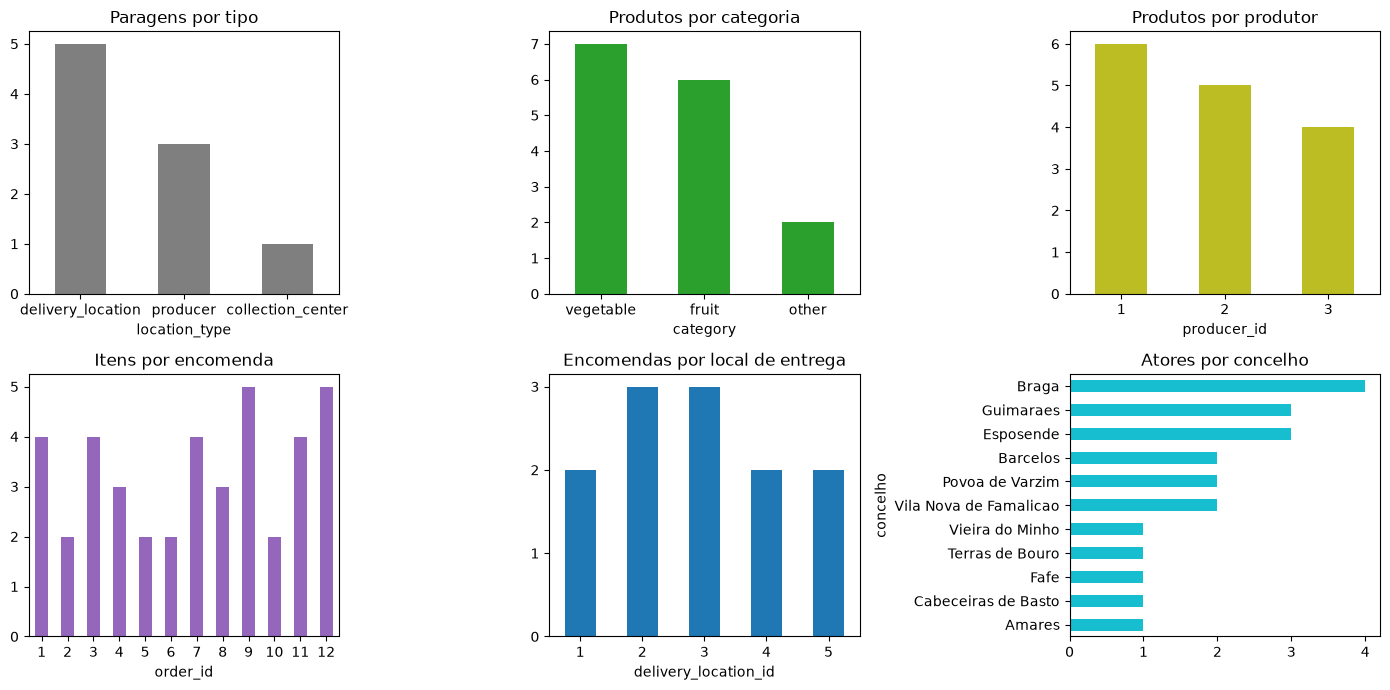

In [4]:
# concelho de cada produtor, cliente, local de entrega e centro (através de localities)
mun = localities.set_index("locality_id")["municipality"]
por_concelho = pd.DataFrame({
    "produtores":        producers["locality_id"].map(mun).value_counts(),
    "clientes":          customers["locality_id"].map(mun).value_counts(),
    "locais de entrega": deliv_locs["locality_id"].map(mun).value_counts(),
    "centros":           centers["locality_id"].map(mun).value_counts(),
}).fillna(0).astype(int).rename_axis("concelho")
display(por_concelho)

# resumo gráfico das contagens principais
fig, axs = plt.subplots(2, 3, figsize=(14, 7))
locations["location_type"].value_counts().plot.bar(ax=axs[0, 0], rot=0, color="tab:gray", title="Paragens por tipo")
products["category"].value_counts().plot.bar(ax=axs[0, 1], rot=0, color="tab:green", title="Produtos por categoria")
products["producer_id"].value_counts().sort_index().plot.bar(ax=axs[0, 2], rot=0, color="tab:olive", title="Produtos por produtor")
items["order_id"].value_counts().sort_index().plot.bar(ax=axs[1, 0], rot=0, color="tab:purple", title="Itens por encomenda")
orders["delivery_location_id"].value_counts().sort_index().plot.bar(ax=axs[1, 1], rot=0, color="tab:blue", title="Encomendas por local de entrega")
por_concelho.sum(axis=1).sort_values().plot.barh(ax=axs[1, 2], color="tab:cyan", title="Atores por concelho")
for ax in axs.flat[:5]:
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))     # contagens são inteiras
axs[1, 2].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

### 1.3 Integridade e coerência dos dados
Verificamos que os dados estão completos e coerentes entre tabelas:

1. **valores em falta** e **IDs duplicados**;
2. **referências inválidas** — chaves estrangeiras que apontam para registos inexistentes;
3. **peso coerente** — `weight_kg` deve ser igual a `quantity × unit_weight_kg`;
4. **valores positivos** — quantidades, pesos e capacidades;
5. **paragens** — cada produtor, centro e local de entrega tem exatamente uma entrada em `locations.csv`, com as mesmas coordenadas e concelho da sua localidade.

In [5]:
pks = {"localities": "locality_id", "producers": "producer_id", "products": "product_id",
       "collection_centers": "center_id", "vehicles": "vehicle_id", "customers": "customer_id",
       "delivery_locations": "delivery_location_id", "orders": "order_id",
       "order_items": "order_item_id", "locations": "location_id"}

# (tabela filha, chave estrangeira, tabela pai, chave primária)
fks = [(producers, "locality_id", localities, "locality_id"),
       (products, "producer_id", producers, "producer_id"),
       (centers, "locality_id", localities, "locality_id"),
       (vehicles, "center_id", centers, "center_id"),
       (customers, "locality_id", localities, "locality_id"),
       (deliv_locs, "locality_id", localities, "locality_id"),
       (orders, "customer_id", customers, "customer_id"),
       (orders, "delivery_location_id", deliv_locs, "delivery_location_id"),
       (items, "order_id", orders, "order_id"),
       (items, "product_id", products, "product_id")]

# peso calculado a partir do produto
peso_calc = items["quantity"] * items["product_id"].map(products.set_index("product_id")["unit_weight_kg"])

# cada entidade física deve corresponder a uma paragem com as coordenadas da sua localidade
entidades = pd.concat([producers.assign(location_type="producer", ref_id=producers["producer_id"]),
                       centers.assign(location_type="collection_center", ref_id=centers["center_id"]),
                       deliv_locs.assign(location_type="delivery_location", ref_id=deliv_locs["delivery_location_id"])])
ligacao = (entidades[["location_type", "ref_id", "locality_id"]]
           .merge(locations, on=["location_type", "ref_id"], how="left")
           .merge(localities, on="locality_id", suffixes=("", "_loc")))

verificacoes = {
    "valores em falta":                 sum(int(v.isna().sum().sum()) for v in tables.values()),
    "IDs duplicados":                   sum(int(tables[k][c].duplicated().sum()) for k, c in pks.items()),
    "referências inválidas":            sum(int((~c[fk].isin(p[pk])).sum()) for c, fk, p, pk in fks),
    "peso ≠ quantidade × peso unitário": int((~np.isclose(items["weight_kg"], peso_calc)).sum()),
    "quantidades/pesos ≤ 0":            int((items[["quantity", "weight_kg"]] <= 0).sum().sum()),
    "capacidades ≤ 0":                  int((vehicles["capacity_kg"] <= 0).sum() + (centers["capacity_kg"] <= 0).sum()),
    "entidades sem paragem":            int(ligacao["location_id"].isna().sum()),
    "paragens com coordenadas diferentes da localidade":
        int((~np.isclose(ligacao["latitude"], ligacao["latitude_loc"]) |
             ~np.isclose(ligacao["longitude"], ligacao["longitude_loc"])).sum()),
    "paragens com concelho diferente":  int((ligacao["municipality"] != ligacao["municipality_loc"]).sum()),
}
pd.Series(verificacoes, name="nº de problemas").to_frame()

,nº de problemas
valores em falta,0
IDs duplicados,0
referências inválidas,0
peso ≠ quantidade × peso unitário,0
quantidades/pesos ≤ 0,0
capacidades ≤ 0,0
entidades sem paragem,0
paragens com coordenadas diferentes da localidade,0
paragens com concelho diferente,0


### 1.4 Regras de operação (`rules.csv`)
O ficheiro `rules.csv` define como a operação funciona: o fluxo dos produtos, os tempos de serviço e de manuseamento, o tempo máximo de permanência no armazém e o significado das janelas. Guardamos as regras num dicionário `R` e verificamos se todas as datas dos pedidos estão dentro do horizonte de planeamento.

In [6]:
display(rules)

R = dict(zip(rules["rule"], rules["value"]))                  # regras como dicionário
SERVICO   = float(R["stop_service_min"])                       # min em cada recolha/entrega
ARMAZEM   = float(R["warehouse_handling_min"])                 # min a descarregar (e a carregar)
DWELL_MAX = float(R["max_warehouse_dwell_h"])                  # h máximas no armazém

inicio = pd.Timestamp(R["start_date"])
fim    = inicio + pd.Timedelta(days=int(R["horizon_days"]))
datas  = items[DATE_COLS].stack()
print(f"Horizonte em rules.csv:   {inicio:%d/%m/%Y %H:%M} a {fim:%d/%m/%Y %H:%M}")
print(f"Datas nas janelas:        {datas.min():%d/%m/%Y %H:%M} a {datas.max():%d/%m/%Y %H:%M}")
print("Todas as janelas dentro do horizonte:", bool(datas.between(inicio, fim).all()))
print("Encomendas feitas antes da disponibilidade:",
      bool((items["order_id"].map(orders.set_index("order_id")["order_datetime"]) < items["availability_start"]).all()))

,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the ...
5,max_warehouse_dwell_h,24,max time a product stays in the warehouse (arr...
6,window_semantics,service_start,windows constrain when the service STARTS
7,avg_speed_kmh,45.0,used to build duration_min
8,route_factor,1.3,used to build distance_km
9,generator_seed,1,seed that produced this dataset


Horizonte em rules.csv:   30/10/2026 00:00 a 01/11/2026 00:00
Datas nas janelas:        30/10/2026 07:15 a 31/10/2026 14:15
Todas as janelas dentro do horizonte: True
Encomendas feitas antes da disponibilidade: True


### 1.5 Pedidos de transporte (um por item)
Cada item de encomenda corresponde a um **pedido de transporte**: recolher um produto num produtor, levá-lo ao armazém e entregá-lo no local escolhido pelo cliente. Juntamos cada item ao produto e à encomenda, e traduzimos os ids para os `location_id` de `locations.csv`, que são os identificadores usados na matriz de distâncias:

- `pickup_loc` — paragem do produtor;
- `delivery_loc` — paragem do local de entrega;
- `W` — paragem do centro de recolha (armazém).

Esta tabela será a base da classe `Request` na fase de modelação.

In [7]:
items = items.merge(products[["product_id", "producer_id", "name", "category", "unit"]], on="product_id", how="left")
items = items.merge(orders[["order_id", "customer_id", "delivery_location_id", "status"]], on="order_id", how="left")

# (tipo de paragem, id original) -> location_id da matriz de distâncias
loc_of = {(t, r): l for l, t, r in locations[["location_id", "location_type", "ref_id"]].itertuples(index=False)}
items["pickup_loc"]   = [loc_of[("producer", p)] for p in items["producer_id"]]
items["delivery_loc"] = [loc_of[("delivery_location", d)] for d in items["delivery_location_id"]]
W = loc_of[("collection_center", int(centers["center_id"].iloc[0]))]

items["dia_recolha"] = items["availability_start"].dt.date
items["dia_entrega"] = items["delivery_start"].dt.date
print("Paragem do armazém (W):", W)
items[["order_item_id", "order_id", "name", "quantity", "unit", "weight_kg", "producer_id",
       "pickup_loc", "delivery_loc", "dia_recolha", "dia_entrega"]]

Paragem do armazém (W): 4


,order_item_id,order_id,name,quantity,unit,weight_kg,producer_id,pickup_loc,delivery_loc,dia_recolha,dia_entrega
0,1,1,Curgete,6.3,kg,6.3,2,2,7,2026-10-31,2026-10-31
1,2,1,Cereja,3.7,kg,3.7,1,1,7,2026-10-31,2026-10-31
2,3,1,Cebola,4.9,kg,4.9,3,3,7,2026-10-31,2026-10-31
3,4,1,Castanha,7.1,kg,7.1,3,3,7,2026-10-31,2026-10-31
4,5,2,Cereja,1.8,kg,1.8,1,1,8,2026-10-30,2026-10-31
5,6,2,Curgete,5.0,kg,5.0,3,3,8,2026-10-30,2026-10-31
6,7,3,Batata,6.7,kg,6.7,2,2,6,2026-10-31,2026-10-31
7,8,3,Cebola,2.5,kg,2.5,3,3,6,2026-10-31,2026-10-31
8,9,3,Curgete,3.1,kg,3.1,3,3,6,2026-10-31,2026-10-31
9,10,3,Kiwi,9.3,kg,9.3,1,1,6,2026-10-31,2026-10-31


### 1.6 Encomendas
Analisamos as encomendas como um todo: quantos itens têm, quanto pesam, de quantos produtores diferentes vêm e se todos os itens de uma encomenda partilham a mesma janela de entrega. Isto ajuda a decidir se as entregas devem ser tratadas item a item ou encomenda a encomenda.

,itens,peso_kg,produtores,local_entrega,janelas_entrega,entrega
order_id,,,,,,
1,4,22.0,3,7,1,2026-10-31 10:30:00
2,2,6.8,2,8,1,2026-10-31 07:15:00
3,4,21.6,3,6,1,2026-10-31 11:30:00
4,3,26.3,3,7,1,2026-10-30 11:30:00
5,2,9.3,2,5,1,2026-10-31 10:30:00
6,2,16.7,2,7,1,2026-10-31 10:45:00
7,4,33.5,2,9,1,2026-10-31 10:45:00
8,3,18.8,2,6,1,2026-10-31 09:30:00
9,5,36.7,3,9,1,2026-10-31 08:15:00


Todas as encomendas têm uma única janela de entrega: True
Peso por encomenda: mín 6.8 kg | média 22.5 kg | máx 51.1 kg


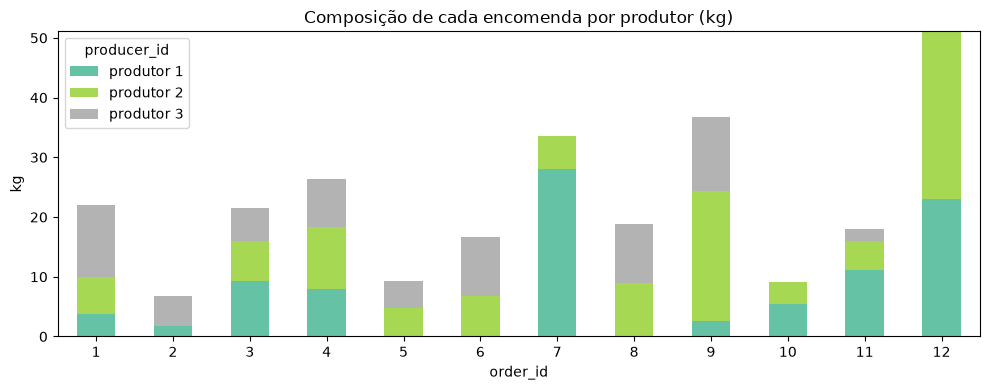

In [8]:
enc = items.groupby("order_id").agg(
    itens=("order_item_id", "count"),
    peso_kg=("weight_kg", "sum"),
    produtores=("producer_id", "nunique"),
    local_entrega=("delivery_loc", "first"),
    janelas_entrega=("delivery_start", "nunique"),
    entrega=("delivery_start", "first"),
)
display(enc)
print("Todas as encomendas têm uma única janela de entrega:", bool((enc["janelas_entrega"] == 1).all()))
print(f"Peso por encomenda: mín {enc.peso_kg.min():.1f} kg | média {enc.peso_kg.mean():.1f} kg | máx {enc.peso_kg.max():.1f} kg")

# peso de cada encomenda, separado pelo produtor de origem
(items.pivot_table(index="order_id", columns="producer_id", values="weight_kg", aggfunc="sum")
      .rename(columns=lambda p: f"produtor {p}")
      .plot.bar(stacked=True, figsize=(10, 4), rot=0, colormap="Set2",
                title="Composição de cada encomenda por produtor (kg)"))
plt.ylabel("kg"); plt.tight_layout(); plt.show()

### 1.7 Janelas temporais
Cada item tem duas janelas: a de **recolha** no produtor (`availability_start`–`availability_end`) e a de **entrega** no cliente (`delivery_start`–`delivery_end`). Segundo `rules.csv`, as janelas restringem o **início** do serviço. Verificamos:

- se cada janela é válida (início antes do fim);
- se a entrega é possível depois de o produto estar disponível;
- se as janelas se sobrepõem (a entrega abre antes de a recolha fechar);
- que itens são entregues num dia diferente do da recolha.

In [9]:
check = pd.DataFrame({
    "recolha_valida":   items["availability_start"] < items["availability_end"],
    "entrega_valida":   items["delivery_start"] < items["delivery_end"],
    "entrega_possivel": items["availability_start"] < items["delivery_end"],
    "sobreposicao":     items["delivery_start"] < items["availability_end"],
    "dia_seguinte":     items["dia_recolha"] != items["dia_entrega"],
})
display(check.sum().to_frame(f"nº de itens (de {len(items)})"))

# duração das janelas, em horas
items["recolha_h"] = (items["availability_end"] - items["availability_start"]).dt.total_seconds() / 3600
items["entrega_h"] = (items["delivery_end"] - items["delivery_start"]).dt.total_seconds() / 3600
display(items[["recolha_h", "entrega_h"]].describe().round(2))

print("Encomendas entregues no dia seguinte:", sorted(items.loc[check["dia_seguinte"], "order_id"].unique().tolist()))

,nº de itens (de 40)
recolha_valida,40
entrega_valida,40
entrega_possivel,40
sobreposicao,10
dia_seguinte,10


,recolha_h,entrega_h
count,40.00,40.00
mean,2.84,2.49
std,0.68,0.58
min,1.75,1.50
25%,2.25,2.25
50%,3.00,2.50
75%,3.50,2.75
max,4.00,3.75


Encomendas entregues no dia seguinte: [2, 8, 9]


O gráfico mostra todas as janelas, com um painel por dia. As barras azuis são janelas de recolha e as laranja de entrega. Os itens estão agrupados por encomenda, o que permite ver que as recolhas de uma mesma encomenda acontecem em produtores diferentes, mas a entrega é comum.

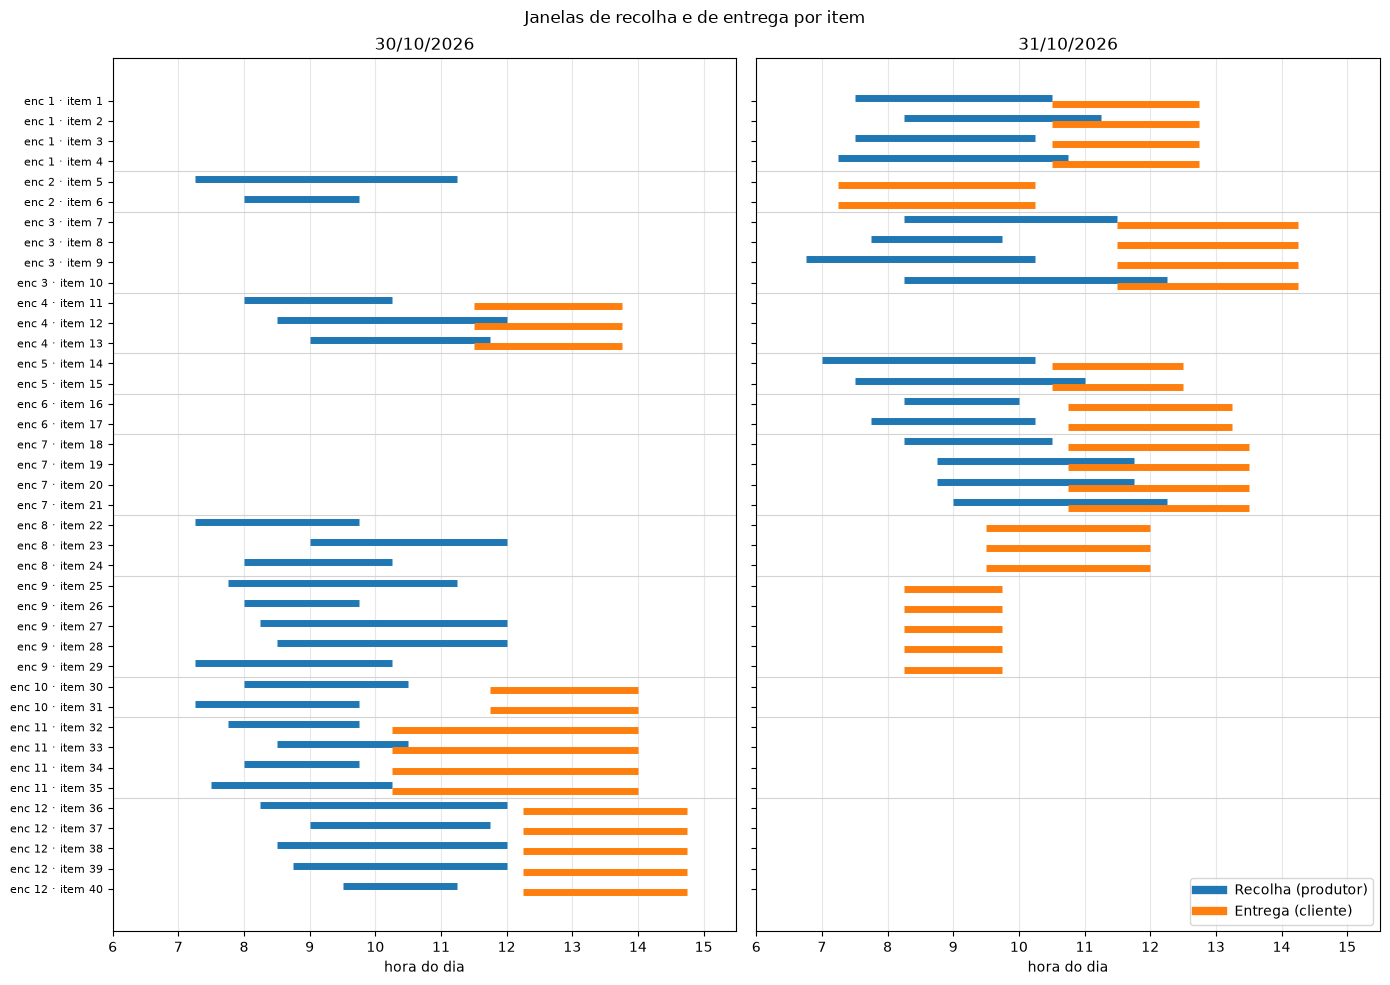

In [10]:
g = items.sort_values(["order_id", "order_item_id"]).reset_index(drop=True)
dias = sorted(set(g["dia_recolha"]) | set(g["dia_entrega"]))
horas = lambda s: s.dt.hour + s.dt.minute / 60                # hora do dia em decimal

fig, axs = plt.subplots(1, len(dias), figsize=(14, 10), sharey=True)
for ax, dia in zip(axs, dias):
    rec = g[g["dia_recolha"] == dia]
    ent = g[g["dia_entrega"] == dia]
    ax.hlines(rec.index - .15, horas(rec["availability_start"]), horas(rec["availability_end"]), color="tab:blue", lw=5)
    ax.hlines(ent.index + .15, horas(ent["delivery_start"]), horas(ent["delivery_end"]), color="tab:orange", lw=5)
    for i in g.index[1:]:                                    # separador entre encomendas
        if g.loc[i, "order_id"] != g.loc[i - 1, "order_id"]:
            ax.axhline(i - .5, color="lightgray", lw=.8)
    ax.set_xlim(6, 15.5); ax.set_xticks(range(6, 16)); ax.grid(axis="x", alpha=.3)
    ax.set_title(f"{dia:%d/%m/%Y}"); ax.set_xlabel("hora do dia")
axs[0].set_yticks(g.index)
axs[0].set_yticklabels([f"enc {o} · item {i}" for o, i in zip(g["order_id"], g["order_item_id"])], fontsize=8)
axs[0].invert_yaxis()
axs[-1].legend(handles=[plt.Line2D([], [], color="tab:blue", lw=6, label="Recolha (produtor)"),
                        plt.Line2D([], [], color="tab:orange", lw=6, label="Entrega (cliente)")], loc="lower right")
plt.suptitle("Janelas de recolha e de entrega por item"); plt.tight_layout(); plt.show()

### 1.8 Matriz de distâncias
A matriz deve conter a distância e o tempo entre **todos os pares ordenados** de paragens. Confirmamos que está completa e simétrica, que respeita a **desigualdade triangular** (ir de A a C diretamente nunca é mais longo do que passar por B — propriedade que usaremos para justificar as heurísticas) e que a velocidade implícita nos tempos é coerente com a dos veículos.

In [11]:
n = len(locations)
print("pares esperados:", n * (n - 1), "| pares no ficheiro:", len(dist))

# matrizes origem x destino (diagonal = 0)
D = dist.pivot(index="origin_location_id", columns="destination_location_id", values="distance_km").fillna(0)
T = dist.pivot(index="origin_location_id", columns="destination_location_id", values="duration_min").fillna(0)
print("simétrica (km / min):", np.allclose(D, D.T), np.allclose(T, T.T))

# desigualdade triangular: d(a,c) <= d(a,b) + d(b,c) para todos os trios (tolerância de arredondamento)
ids = list(D.index)
violacoes = sum(D.loc[a, c] > D.loc[a, b] + D.loc[b, c] + 0.011 for a, b, c in itertools.permutations(ids, 3))
print(f"desigualdade triangular: {violacoes} violações em {n * (n - 1) * (n - 2)} trios")

print(f"distância (km): mín {dist.distance_km.min():.1f} | média {dist.distance_km.mean():.1f} | máx {dist.distance_km.max():.1f}")
v = dist[dist.duration_min > 0]
print("velocidade implícita (km/h):", sorted(float(x) for x in (v.distance_km / (v.duration_min / 60)).round(0).unique()),
      "| vehicles.csv:", vehicles["avg_speed_kmh"].tolist())

# pares com distância zero (paragens no mesmo local)
zeros = dist.loc[dist.distance_km == 0, "origin_location_id"].unique()
display(locations[locations["location_id"].isin(zeros)])

# distância do armazém a cada paragem
locations.assign(km_ao_armazem=locations["location_id"].map(D.loc[W])).query("location_id != @W")[
    ["location_id", "location_type", "name", "municipality", "km_ao_armazem"]].sort_values("km_ao_armazem")

pares esperados: 72 | pares no ficheiro: 72
simétrica (km / min): True True
desigualdade triangular: 0 violações em 504 trios
distância (km): mín 0.0 | média 33.5 | máx 71.5
velocidade implícita (km/h): [45.0] | vehicles.csv: [45.0, 45.0]


,location_id,location_type,ref_id,name,municipality,latitude,longitude
6,7,delivery_location,3,Casa 3,Guimaraes,41.418772,-8.289729
8,9,delivery_location,5,Loja 5,Guimaraes,41.418772,-8.289729


,location_id,location_type,name,municipality,km_ao_armazem
4,5,delivery_location,Loja 1,Guimaraes,18.79
7,8,delivery_location,Casa 4,Vila Nova de Famalicao,21.39
6,7,delivery_location,Casa 3,Guimaraes,23.53
8,9,delivery_location,Loja 5,Guimaraes,23.53
2,3,producer,Horta Morais,Terras de Bouro,29.06
0,1,producer,Hortas Valente,Fafe,30.60
5,6,delivery_location,Casa 2,Esposende,36.12
1,2,producer,Campos Leite,Vieira do Minho,37.66


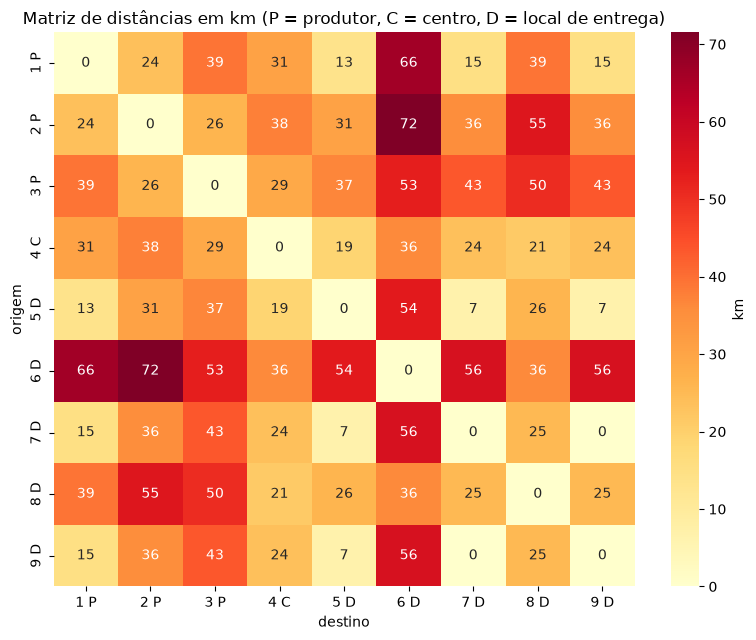

In [12]:
lbl = {r.location_id: f"{r.location_id} {'PCD'[['producer', 'collection_center', 'delivery_location'].index(r.location_type)]}"
       for r in locations.itertuples()}
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(D.rename(index=lbl, columns=lbl), annot=True, fmt=".0f", cmap="YlOrRd", ax=ax, cbar_kws={"label": "km"})
ax.set_xlabel("destino"); ax.set_ylabel("origem")
ax.set_title("Matriz de distâncias em km (P = produtor, C = centro, D = local de entrega)")
plt.tight_layout(); plt.show()

### 1.9 Mapa das paragens e dos fluxos
Produtores a verde, centro de recolha a vermelho e locais de entrega a azul. As linhas representam o fluxo obrigatório de mercadoria: dos produtores para o armazém (verde) e do armazém para os locais de entrega (azul). A espessura é proporcional aos kg transportados. Passar o rato sobre um ponto ou linha mostra os detalhes.

In [13]:
cores = {"producer": "green", "collection_center": "red", "delivery_location": "blue"}
pos = locations.set_index("location_id")[["latitude", "longitude"]]
m = folium.Map(location=[pos.latitude.mean(), pos.longitude.mean()], zoom_start=10)

# fluxos produtor -> armazém e armazém -> local de entrega, com espessura proporcional ao peso
for loc_id, kg in items.groupby("pickup_loc")["weight_kg"].sum().items():
    folium.PolyLine([pos.loc[loc_id].tolist(), pos.loc[W].tolist()], color="green", weight=2 + kg / 10,
                    opacity=.6, tooltip=f"paragem {loc_id} → armazém: {kg:.1f} kg").add_to(m)
for loc_id, kg in items.groupby("delivery_loc")["weight_kg"].sum().items():
    folium.PolyLine([pos.loc[W].tolist(), pos.loc[loc_id].tolist()], color="blue", weight=2 + kg / 10,
                    opacity=.5, tooltip=f"armazém → paragem {loc_id}: {kg:.1f} kg").add_to(m)

# paragens no mesmo local partilham um marcador
for (lat, lon), grp in locations.groupby(["latitude", "longitude"]):
    folium.CircleMarker([lat, lon], radius=9, color=cores[grp["location_type"].iloc[0]], fill=True, fill_opacity=.9,
                        tooltip=" | ".join(f"{r.location_id} · {r.name} ({r.municipality})" for r in grp.itertuples())
                        ).add_to(m)
m

### 1.10 Carga face à capacidade
Comparamos o peso a transportar com a capacidade dos veículos. Como todos os produtos passam pelo armazém, a carga divide-se em dois tipos de viagem: **recolhas** (produtores → armazém) e **entregas** (armazém → clientes). Agrupamos o peso pelo dia de cada uma.

,recolhas_kg,entregas_kg,total_kg,recolhas % veíc. 1,recolhas % veíc. 2,recolhas % frota
dia,,,,,,
2026-10-30,166.9,104.6,271.5,111.3,83.4,47.7
2026-10-31,103.1,165.4,268.5,68.7,51.6,29.5


Peso total: 270.0 kg | capacidade da frota: 350.0 kg (veículo 1: 150 kg, veículo 2: 200 kg)
Maior encomenda: 51.1 kg | menor veículo: 150 kg
Capacidade do armazém: 5000 kg


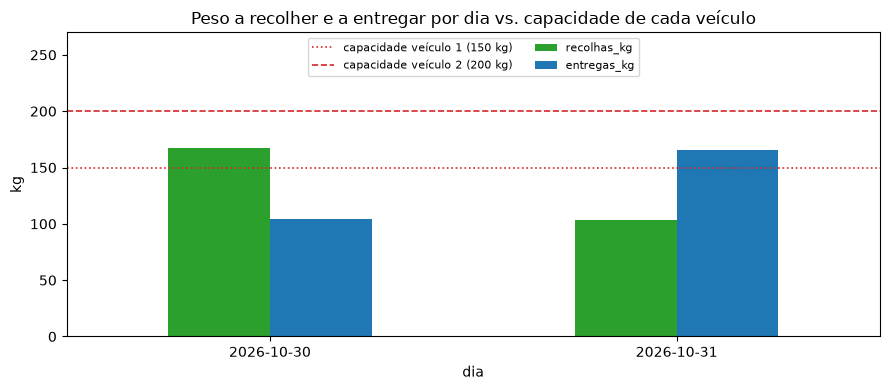

In [14]:
cap = vehicles.set_index("vehicle_id")["capacity_kg"]
carga = pd.DataFrame({
    "recolhas_kg": items.groupby("dia_recolha")["weight_kg"].sum(),
    "entregas_kg": items.groupby("dia_entrega")["weight_kg"].sum(),
}).rename_axis("dia")
carga["total_kg"] = carga.sum(axis=1)
for vid, c in cap.items():
    carga[f"recolhas % veíc. {vid}"] = (100 * carga["recolhas_kg"] / c).round(1)
carga["recolhas % frota"] = (100 * carga["recolhas_kg"] / cap.sum()).round(1)
display(carga)

print(f"Peso total: {items.weight_kg.sum():.1f} kg | capacidade da frota: {cap.sum():.1f} kg "
      f"({', '.join(f'veículo {k}: {v:.0f} kg' for k, v in cap.items())})")
print(f"Maior encomenda: {enc.peso_kg.max():.1f} kg | menor veículo: {cap.min():.0f} kg")
print(f"Capacidade do armazém: {centers.capacity_kg.iloc[0]:.0f} kg")

ax = carga[["recolhas_kg", "entregas_kg"]].plot.bar(figsize=(9, 4), rot=0, color=["tab:green", "tab:blue"])
for (vid, c), ls in zip(cap.items(), [":", "--"]):
    ax.axhline(c, color="tab:red", ls=ls, lw=1.2, label=f"capacidade veículo {vid} ({c:.0f} kg)")
ax.set_ylim(0, cap.max() * 1.35); ax.set_ylabel("kg")
ax.set_title("Peso a recolher e a entregar por dia vs. capacidade de cada veículo")
ax.legend(loc="upper center", ncol=2, fontsize=8); plt.tight_layout(); plt.show()

### 1.11 Viabilidade de cada pedido
Antes de procurar rotas, verificamos se **cada pedido pode ser cumprido isoladamente**, no melhor caso.

**Itens entregues no próprio dia.** O veículo recolhe assim que o produto fica disponível e segue sem desvios: produtor (10 min de serviço) → armazém (15 min a descarregar + 15 min a carregar) → cliente. A *folga* é o tempo entre a chegada ao cliente e o fecho da janela de entrega; uma folga negativa significa um pedido impossível.

**Itens entregues no dia seguinte.** Ficam a noite no armazém e o tempo entre a chegada ao armazém e o início do carregamento não pode passar de 24 h. Calculamos o intervalo de permanência possível:

- **mínima** — recolha o mais tarde possível e carregamento apenas a tempo de chegar quando a janela de entrega abre;
- **máxima** — recolha o mais cedo possível e carregamento o mais tarde possível.

In [15]:
# tempo de viagem (min) entre duas paragens
t = lambda a, b: T.loc[a, b]
ida_armazem = items["pickup_loc"].map(lambda p: t(p, W))      # produtor -> armazém
ida_cliente = items["delivery_loc"].map(lambda d: t(W, d))    # armazém -> cliente
min_ = lambda s: pd.to_timedelta(s, unit="min")

# --- itens entregues no próprio dia
mesmo_dia = items["dia_recolha"] == items["dia_entrega"]
chegada = items["availability_start"] + min_(SERVICO + ida_armazem + 2 * ARMAZEM + ida_cliente)
items["folga_min"] = np.where(mesmo_dia, (items["delivery_end"] - chegada).dt.total_seconds() / 60, np.nan)
print(f"Itens entregues no próprio dia: {int(mesmo_dia.sum())} | impossíveis: {int((items['folga_min'] < 0).sum())} | "
      f"folga mínima: {items['folga_min'].min():.0f} min")

# --- itens entregues no dia seguinte: permanência no armazém (h)
chega_cedo  = items["availability_start"] + min_(SERVICO + ida_armazem)
chega_tarde = items["availability_end"]   + min_(SERVICO + ida_armazem)
carrega_cedo  = items["delivery_start"] - min_(ARMAZEM + ida_cliente)
carrega_tarde = items["delivery_end"]   - min_(ARMAZEM + ida_cliente)
items["perm_min_h"] = ((carrega_cedo - chega_tarde).dt.total_seconds() / 3600).where(~mesmo_dia)
items["perm_max_h"] = ((carrega_tarde - chega_cedo).dt.total_seconds() / 3600).where(~mesmo_dia)
pern = items.loc[~mesmo_dia, ["order_item_id", "order_id", "perm_min_h", "perm_max_h"]].round(2)
print(f"Itens entregues no dia seguinte: {len(pern)} | impossíveis (permanência mínima > {DWELL_MAX:.0f} h): "
      f"{int((pern.perm_min_h > DWELL_MAX).sum())} | com combinações proibidas (máxima > {DWELL_MAX:.0f} h): "
      f"{int((pern.perm_max_h > DWELL_MAX).sum())}")
display(pern)

Itens entregues no próprio dia: 30 | impossíveis: 0 | folga mínima: 158 min
Itens entregues no dia seguinte: 10 | impossíveis (permanência mínima > 24 h): 0 | com combinações proibidas (máxima > 24 h): 8


,order_item_id,order_id,perm_min_h,perm_max_h
4,5,2,18.43,25.43
5,6,2,19.96,24.71
21,22,8,21.88,26.88
22,23,8,19.44,24.94
23,24,8,21.38,26.14
24,25,9,19.38,24.38
25,26,9,20.92,24.16
26,27,9,18.47,23.72
27,28,9,18.47,23.47
28,29,9,20.42,24.92


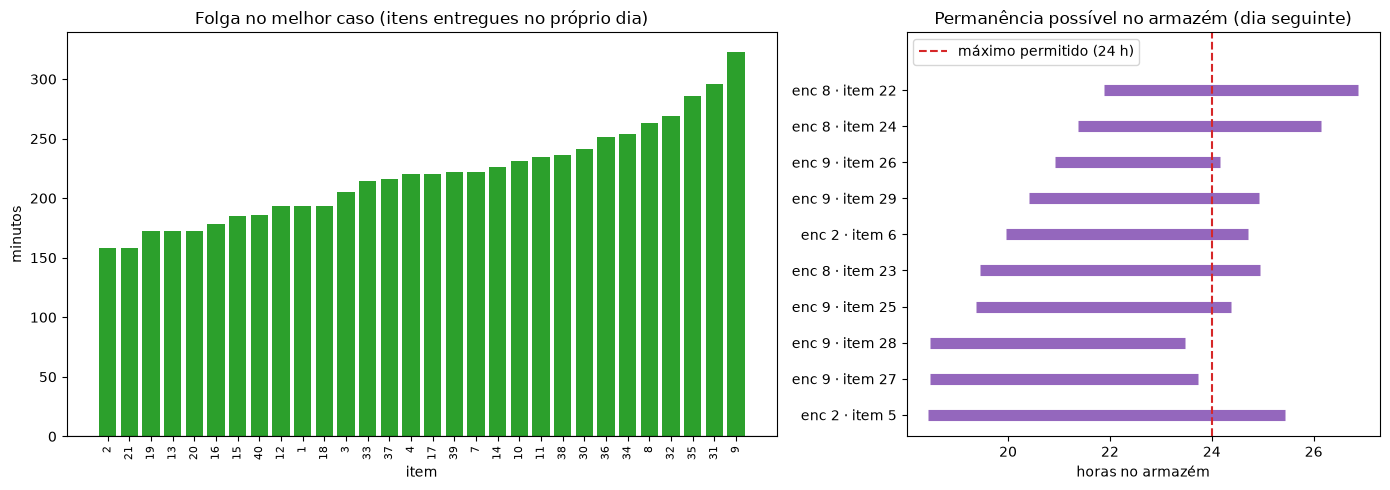

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [3, 2]})

# folga dos itens entregues no próprio dia
f = items.loc[mesmo_dia].sort_values("folga_min")
axs[0].bar(f["order_item_id"].astype(str), f["folga_min"], color="tab:green")
axs[0].axhline(0, color="black", lw=.8)
axs[0].set_xlabel("item"); axs[0].set_ylabel("minutos")
axs[0].set_title("Folga no melhor caso (itens entregues no próprio dia)")
axs[0].tick_params(axis="x", labelsize=8, rotation=90)

# intervalo de permanência possível dos itens que passam a noite no armazém
p = pern.sort_values("perm_min_h").reset_index(drop=True)
axs[1].hlines(p.index, p["perm_min_h"], p["perm_max_h"], color="tab:purple", lw=8)
axs[1].axvline(DWELL_MAX, color="tab:red", ls="--", label=f"máximo permitido ({DWELL_MAX:.0f} h)")
axs[1].set_yticks(p.index)
axs[1].set_yticklabels([f"enc {o} · item {i}" for o, i in zip(p["order_id"], p["order_item_id"])])
axs[1].set_ylim(-0.6, len(p) + 0.6)                          # espaço livre para a legenda
axs[1].set_xlabel("horas no armazém"); axs[1].legend(loc="upper left")
axs[1].set_title("Permanência possível no armazém (dia seguinte)")
plt.tight_layout(); plt.show()

### 1.12 Comparação com o conjunto *small*
Repetimos a leitura para o conjunto *small* e comparamos os indicadores principais, para antecipar como o problema escala nas fases seguintes.

In [17]:
def resumo(pasta):
    """Indicadores principais de um conjunto de dados."""
    t = carregar(pasta)
    it, veh = t["order_items"], t["vehicles"]
    return {
        "produtores": len(t["producers"]), "locais de entrega": len(t["delivery_locations"]),
        "paragens": len(t["locations"]), "clientes": len(t["customers"]), "produtos": len(t["products"]),
        "encomendas": len(t["orders"]), "itens": len(it), "veículos": len(veh),
        "dias": it["availability_start"].dt.date.nunique(),
        "peso total (kg)": round(it["weight_kg"].sum(), 1),
        "capacidade da frota (kg)": veh["capacity_kg"].sum(),
        "peso / capacidade (%)": round(100 * it["weight_kg"].sum() / veh["capacity_kg"].sum(), 1),
        "itens entregues no dia seguinte": int((it["availability_start"].dt.date != it["delivery_start"].dt.date).sum()),
    }

# Series com dtype=object para manter os inteiros sem casas decimais
pd.DataFrame({"tiny":  pd.Series(resumo("docs/data_tiny/"), dtype=object),
              "small": pd.Series(resumo("docs/data_small_30_31oct2026/"), dtype=object)})

,tiny,small
produtores,3,6
locais de entrega,5,7
paragens,9,14
clientes,12,21
produtos,15,31
encomendas,12,25
itens,40,80
veículos,2,2
dias,2,2
peso total (kg),270.0,580.0


### 1.13 Conclusões da EDA

**Leitura e qualidade dos dados.** Os 12 ficheiros são lidos sem problemas e as datas convertidas para `datetime`. Não há valores em falta, IDs duplicados nem referências inválidas; o peso de cada item é coerente com `quantity × unit_weight_kg`; cada paragem tem as coordenadas e o concelho da sua localidade. Os dados podem ser usados sem limpeza.

**Composição do problema.** 9 paragens (3 produtores, 1 centro de recolha em Braga e 5 locais de entrega), 15 produtos, 12 clientes e 12 encomendas com 40 itens, num total de **270 kg**, a planear em **2 dias** (30 e 31 de outubro) com 2 veículos: um refrigerado de 150 kg e outro de 200 kg. Todas as datas estão dentro do horizonte de `rules.csv`.

**As encomendas obrigam à consolidação no armazém.** Cada encomenda junta produtos de 2 ou 3 produtores e todos os seus itens partilham a mesma janela de entrega. Isto justifica o fluxo produtor → armazém → cliente e permite tratar a **entrega por encomenda** (12 entregas) e a **recolha por produtor** (no máximo 3 produtores por dia), o que reduz muito o número de paragens a ordenar.

**A capacidade passa a ser uma restrição real.** No dia 30 há 166,9 kg para recolher, mais do que a capacidade do veículo 1 (150 kg) e 48% da frota; no dia 31 há 165,4 kg para entregar. A maior encomenda (51,1 kg) cabe em qualquer veículo e o armazém (5000 kg) nunca é limitante. A divisão da carga entre veículos, ou várias viagens, terá de ser decidida pelos algoritmos.

**Janelas temporais.** Todas são válidas. As de recolha duram 1,75 a 4 h e as de entrega 1,5 a 3,75 h. Em 10 itens as janelas sobrepõem-se e 10 itens (encomendas 2, 8 e 9) são recolhidos no dia 30 e entregues no dia 31.

**Todos os pedidos são exequíveis isoladamente.** Os 30 itens entregues no próprio dia têm, no melhor caso, pelo menos 158 min de folga mesmo passando pelo armazém. Os 10 itens entregues no dia seguinte conseguem respeitar o limite de 24 h no armazém, mas por pouco: a permanência mínima já é de 18,5 a 21,9 h, e em 8 deles algumas combinações (recolher cedo e entregar tarde) ultrapassam as 24 h. O limite de permanência é, por isso, uma restrição ativa que o CSP terá de modelar.

**Matriz de distâncias.** Completa (72 pares para 9 paragens), simétrica e sem violações da desigualdade triangular, o que garante que as heurísticas baseadas em distância serão admissíveis. Os tempos usam 45 km/h, a mesma velocidade dos veículos. As paragens 7 (Casa 3) e 9 (Loja 5) ficam no mesmo local em Guimarães (distância 0) e podem ser servidas na mesma passagem.

**Pontos a confirmar com o docente.** O veículo 1 é refrigerado, mas nenhum produto indica necessitar de frio: assumimos que ambos os veículos podem transportar qualquer produto.

**Escala.** O conjunto *small* tem o dobro dos itens e encomendas e o peso total (580 kg) ultrapassa a capacidade da frota (550 kg), pelo que aí a capacidade será ainda mais determinante e os veículos terão de fazer várias viagens.